In [1]:
import os, sys
from pathlib import Path

# Localizar a raiz do projeto (pasta que contém "src/") para poder importar os módulos auxiliares
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
print("Raiz do projeto:", PROJECT_ROOT)

Raiz do projeto: C:\Users\josepires\Downloads\Projeto  IA III\IA3_Projeto-José


# 4. Evaluation (Metodologia CRISP-ML)

## 4.1. Avaliação comparativa dos modelos persistidos
Carrega o conjunto de teste (20% mais recente) e todos os modelos guardados em `models/`, faz uma avaliação multicritério
e gera o manifesto do modelo campeão (`models_manifest.json`).

## 4.2. Métricas por modelo

In [2]:
from src import evaluate_models as ev
df_eval, scores, y_te = ev.avaliar_modelos_guardados()
df_eval.drop(columns=["Melhores Hiperparâmetros", "Ficheiro", "Escalado"])

,Modelo,Tipo,Accuracy (%),Precision Fraude (%),Recall Fraude (%),F1 Fraude (%),ROC-AUC (%),PR-AUC (%),MCC
0,Random Forest,Machine Learning,99.96,98.15,71.62,82.81,98.62,81.41,0.8383
1,TensorFlow Neural Net,Deep Learning,99.10,11.23,85.14,19.84,95.49,79.40,0.3073
2,KNN,Machine Learning,99.94,76.71,75.68,76.19,93.15,79.33,0.7616
3,Logistic Regression,Machine Learning,95.63,2.68,91.89,5.20,98.71,75.92,0.1528
4,Decision Tree,Machine Learning,99.17,11.11,77.03,19.42,88.41,70.99,0.2906
5,SVM,Machine Learning,99.88,52.43,72.97,61.02,96.70,69.06,0.6180
6,Gradient Boosting,Machine Learning,99.89,55.21,71.62,62.35,98.42,38.34,0.6283
7,Naive Bayes,Machine Learning,98.01,5.03,79.73,9.46,96.79,6.19,0.1972


## 4.3. Curvas Precision-Recall e matriz de confusão do campeão

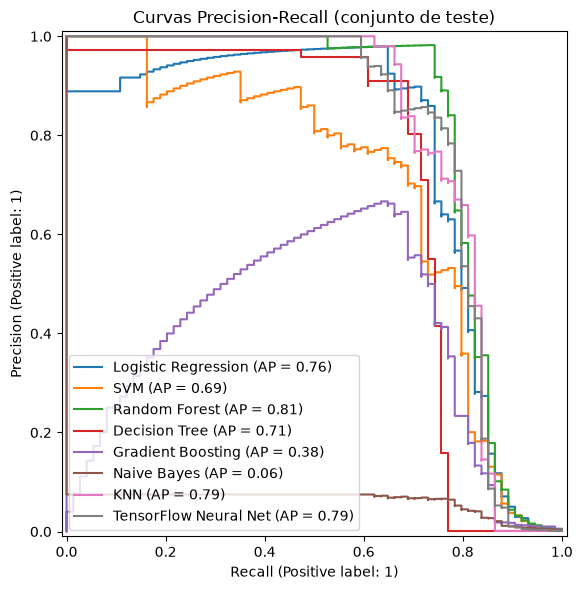

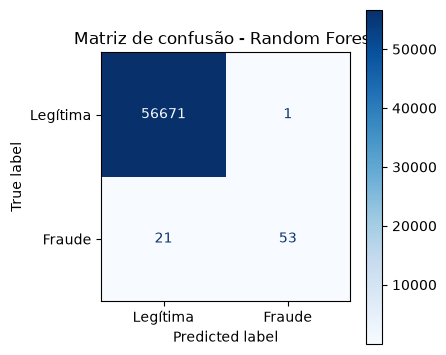

In [3]:
ev.graficos_avaliacao(df_eval, scores, y_te)

## 4.4. Manifesto e modelo campeão
Critério: **maior PR-AUC** (independente do limiar); o limiar de decisão por defeito é 0.5.

In [4]:
meta = ev.guardar_manifesto(df_eval)
meta["melhor_modelo"]

Manifesto exportado para: C:\Users\josepires\Downloads\Projeto  IA III\IA3_Projeto-José\models\models_manifest.json
Modelo Campeão: Random Forest (random_forest_opt.joblib)


{'nome': 'Random Forest',
 'ficheiro': 'random_forest_opt.joblib',
 'escalado': False,
 'pr_auc': 81.41,
 'f1_fraude': 82.81,
 'recall_fraude': 71.62,
 'precision_fraude': 98.15}

## 4.4.1. Os dois melhores modelos por F1 e ROC-AUC
O campeão é escolhido por PR-AUC (4.4); aqui listam-se também os 2 melhores por F1 da fraude e por ROC-AUC.

In [5]:
melhores = ev.dois_melhores(df_eval)
for metrica, tabela in melhores.items():
    print(metrica)
    print(tabela.to_string(index=False), "\n")

F1 Fraude (%)
       Modelo  F1 Fraude (%)
Random Forest          82.81
          KNN          76.19 

ROC-AUC (%)
             Modelo  ROC-AUC (%)
Logistic Regression        98.71
      Random Forest        98.62 



## 4.5. Simulação de deployment
O módulo `src/predict.py` carrega o campeão a partir do manifesto e classifica transações.
Exemplo com uma fraude e uma transação legítima reais do teste.

In [6]:
import pandas as pd
from src.config import MODELS_DIR, TEST_FILE
from src.predict import PredictorFraude

predictor = PredictorFraude(MODELS_DIR)
teste = pd.read_csv(TEST_FILE)
for rotulo, classe in [("Fraude real", 1), ("Legítima real", 0)]:
    linha = teste[teste["Class"] == classe].iloc[0]
    print(rotulo, "->", predictor.prever(linha.drop("Class").to_dict()))

Fraude real -> {'modelo': 'Random Forest', 'previsao': 'Fraude', 'probabilidade_fraude_%': 96.96, 'limiar_%': 50.0}
Legítima real -> {'modelo': 'Random Forest', 'previsao': 'Legítima', 'probabilidade_fraude_%': 1.54, 'limiar_%': 50.0}


## 4.6. Conclusões
- A accuracy é inútil neste problema (todos os modelos > 99%); decide-se por **PR-AUC / Recall / Precision** da fraude.
- O trade-off Precision/Recall pode ser ajustado alterando `limiar_decisao` no manifesto, conforme o custo de falsos positivos vs. fraudes não detetadas.
- Limitações: poucas fraudes no teste (74), features anonimizadas (PCA) e amostragem nos modelos mais pesados.